Name Muhtasim Haque Nahian

Labpartner(s) Taherunnesa Rahi

In [13]:
#import statements go here
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, PercentFormatter, MaxNLocator

# Class 8.1

Today we are presenting movies! The homework is to work on your proposals. 


**W.1** This week our warmups are focused on applying your Pandas skills. Please download the 2026 World Cup player stats from slack (pinned to #announcements), and do some analyisis on this, whatever you are keen on. We'll do more with this on Wednesday. Show your work and make sure you write some text about what you found. 

In [3]:
# Load data

players = pd.read_csv("player_stats.csv")
display(players.head())

print("Number of rows:", players.shape[0])
print("Number of columns:", players.shape[1])

players.info()

display(players.describe())

,player_id,player_name,team_id,position,matches_played,matches_started,minutes_played,goals,assists,shots,...,yellow_cards,red_cards,penalty_goals,own_goals,clean_sheets,saves,goals_conceded,average_rating,data_source,last_verified
0,1,José Raúl Rangel,1,GK,5,5,438,0,0,NaN,...,0,0,0,0,4.0,7.0,3.0,NaN,sofascore.com,2026-07-19
1,2,Jorge Eduardo Sanchez,1,DEF,5,5,439,0,1,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
2,3,César Jasib Montes,1,DEF,3,2,165,0,0,NaN,...,0,1,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
3,4,Edson Omar Alvarez,1,DEF,2,0,75,0,0,NaN,...,1,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
4,5,Johan Felipe Vasquez,1,DEF,2,2,180,0,0,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19


Number of rows: 1248
Number of columns: 21
<class 'pandas.DataFrame'>
RangeIndex: 1248 entries, 0 to 1247
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   player_id        1248 non-null   int64  
 1   player_name      1248 non-null   str    
 2   team_id          1248 non-null   int64  
 3   position         1248 non-null   str    
 4   matches_played   1248 non-null   int64  
 5   matches_started  1248 non-null   int64  
 6   minutes_played   1248 non-null   int64  
 7   goals            1248 non-null   int64  
 8   assists          1248 non-null   int64  
 9   shots            0 non-null      float64
 10  shots_on_target  0 non-null      float64
 11  yellow_cards     1248 non-null   int64  
 12  red_cards        1248 non-null   int64  
 13  penalty_goals    1248 non-null   int64  
 14  own_goals        1248 non-null   int64  
 15  clean_sheets     145 non-null    float64
 16  saves            145 non-nul

,player_id,team_id,matches_played,matches_started,minutes_played,goals,assists,shots,shots_on_target,yellow_cards,red_cards,penalty_goals,own_goals,clean_sheets,saves,goals_conceded,average_rating
count,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,0.0,0.0,1248.000000,1248.000000,1248.0,1248.000000,145.00000,145.000000,145.000000,0.0
mean,624.500000,24.500000,2.564103,1.833333,168.997596,0.235577,0.163462,NaN,NaN,0.028045,0.009615,0.0,0.011218,0.37931,4.772414,2.165517,NaN
std,360.410877,13.858953,1.782673,1.771496,152.687113,0.766552,0.540763,NaN,NaN,0.165167,0.097625,0.0,0.112716,0.85040,6.674729,2.908354,NaN
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,NaN
25%,312.750000,12.750000,1.000000,0.000000,23.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,NaN
50%,624.500000,24.500000,3.000000,2.000000,146.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,NaN
75%,936.250000,36.250000,4.000000,3.000000,270.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.0,0.000000,0.00000,8.000000,4.000000,NaN
max,1248.000000,48.000000,8.000000,8.000000,750.000000,10.000000,8.000000,NaN,NaN,1.000000,1.000000,0.0,2.000000,5.00000,29.000000,10.000000,NaN


In [4]:
# Calculate each player's total goal contributions
players["goal_contributions"] = players["goals"] + players["assists"]

# Find the top 10 players by goal contributions
top_contributors = players.sort_values("goal_contributions", ascending=False).head(10)

display(top_contributors)

,player_id,player_name,team_id,position,matches_played,matches_started,minutes_played,goals,assists,shots,...,red_cards,penalty_goals,own_goals,clean_sheets,saves,goals_conceded,average_rating,data_source,last_verified,goal_contributions
841,842,Kylian Mbappe,33,FWD,8,8,711,10,4,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,14
945,946,Lionel Andrés Messi,37,FWD,8,5,590,8,4,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,12
842,843,Michael Akpovie Olise,33,FWD,8,8,668,0,8,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,8
1153,1154,Jude Victor William Bellingham,45,MID,8,7,596,7,1,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,8
838,839,Masour Ousmane Dembele,33,FWD,6,4,363,5,2,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,7
918,919,Erling Braut Haaland,36,FWD,5,5,450,7,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,7
1152,1153,Harry Edward Kane,45,FWD,6,6,534,6,1,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,7
748,749,Mikel Oyarzabal,29,FWD,6,5,394,5,1,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,6
1150,1151,Bukayo Ayoyinka Saka,45,FWD,7,4,373,3,3,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,6
190,191,Johan Kula Manzambi,8,MID,6,4,378,3,2,NaN,...,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19,5


## Attacking Profiles: to see whether the players were scorers, creators, or both?

I compared players’ scoring and playmaking using **non-penalty goals and assists per 90 minutes**. I excluded goalkeepers, players with fewer than 270 minutes, and records missing the required statistics, leaving 313 eligible players.

I calculated each rate by dividing the player’s total by minutes played and multiplying by 90. Non-penalty goals were calculated by subtracting penalty goals from total goals.

I used a **bubble scatter plot** with assists per 90 on the x-axis and non-penalty goals per 90 on the y-axis. Bubble size represents minutes played, while color represents the combined rate of non-penalty goals and assists. I highlighted the eight players with the highest combined rates.

I used minutes-weighted means to draw the dashed reference lines. This gives greater weight to players with more playing time.

$$
\text{Weighted rate per 90}
= \frac{\sum_i w_i r_i}{\sum_i w_i}
= \frac{\sum_i S_i}{\sum_i M_i}\times90
$$

Here, $S_i$ is a player's statistic, $M_i$ is their minutes played, $r_i = 90S_i/M_i$ is their per-90 rate, and $w_i=M_i$ is their weight.

**Vertical dashed line:**

$$
\text{Assists benchmark}
= \frac{\sum_i \text{Assists}_i}{\sum_i \text{Minutes}_i}\times90
$$

**Horizontal dashed line:**

$$
\text{Scoring benchmark}
= \frac{\sum_i(\text{Goals}_i-\text{Penalty goals}_i)}
{\sum_i \text{Minutes}_i}\times90
$$

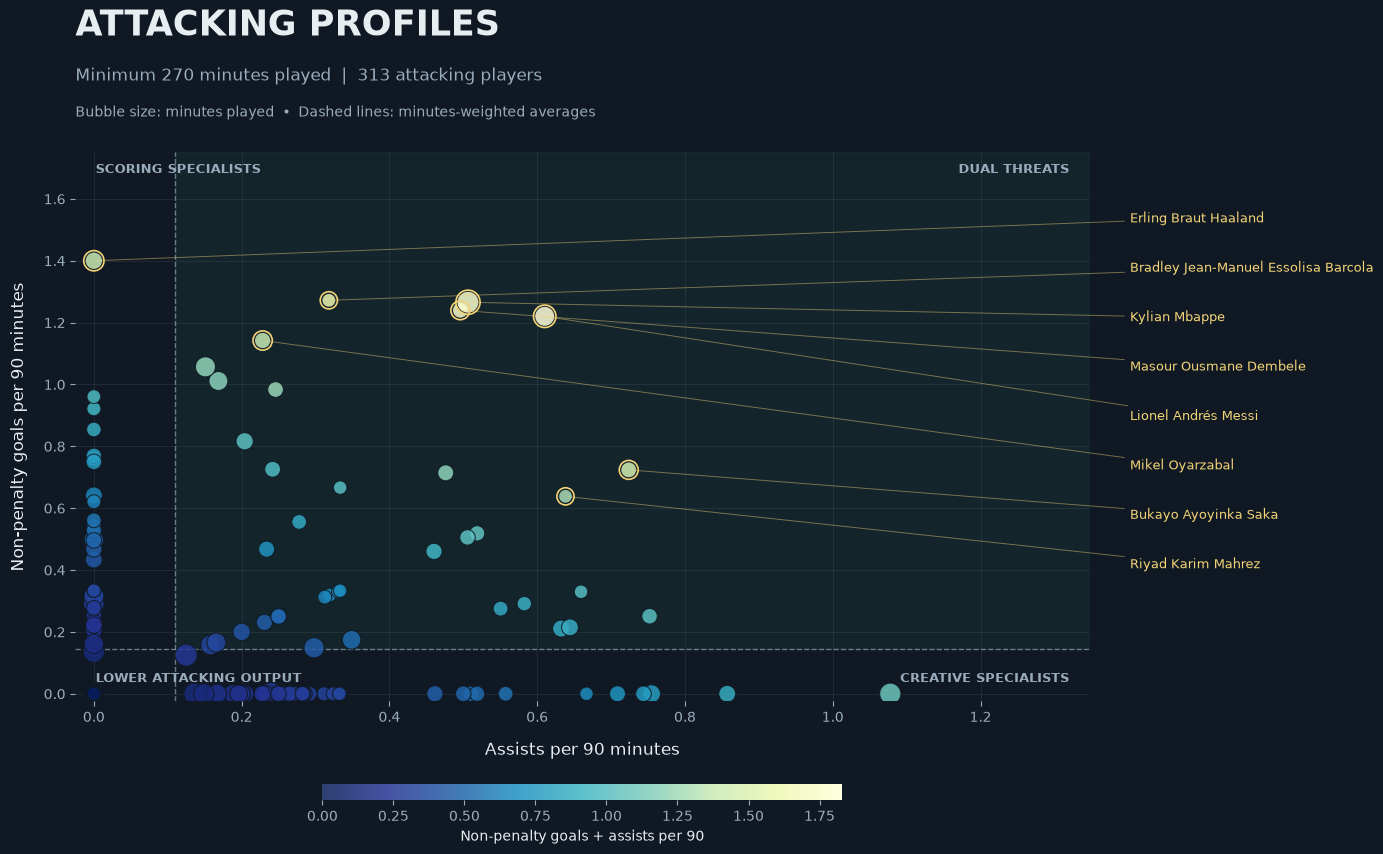

In [5]:
stats = ["minutes_played", "goals", "assists", "penalty_goals"]
attack = players.copy()
attack[stats] = attack[stats].apply(pd.to_numeric, errors="coerce")

# Keep players with at least 270 minutes and complete required statistics
attack = attack.dropna(subset=stats)
attack = attack[(attack["minutes_played"] >= 270) & (~attack["position"].fillna("").str.upper().isin(["GK", "GOALKEEPER"]))].copy()

attack["non_penalty_goals"] = attack["goals"] - attack["penalty_goals"]
attack = attack[attack["non_penalty_goals"] >= 0].copy()

# Calculate attacking output per 90 minutes
attack["npg_per90"] = (attack["non_penalty_goals"] / attack["minutes_played"] * 90)
attack["assists_per90"] = (attack["assists"] / attack["minutes_played"] * 90)
attack["contributions_per90"] = (attack["npg_per90"] + attack["assists_per90"])

if attack.empty:
    raise ValueError("No players meet the minutes and data requirements.")

# Minutes-weighted benchmarks for the selected players
avg_npg = attack["non_penalty_goals"].sum() / attack["minutes_played"].sum() * 90
avg_assists = attack["assists"].sum() / attack["minutes_played"].sum() * 90

# Label the eight players with the highest combined attacking rate
standouts = attack.nlargest(8, "contributions_per90")

# Chart styling
background = "#101923"
text_color = "#E8EDF2"
muted = "#9AABBC"

with plt.rc_context({"font.family": "DejaVu Sans","text.color": text_color, "axes.labelcolor": text_color,
    "xtick.color": muted, "ytick.color": muted}):
    fig, ax = plt.subplots(figsize=(13, 9), facecolor=background)
    ax.set_facecolor(background)
    fig.subplots_adjust(left=0.09, right=0.87, top=0.81, bottom=0.20)

    xmax = max(0.5, attack["assists_per90"].max() * 1.25)
    ymax = max(0.5, attack["npg_per90"].max() * 1.25)

    # Shade the area above both benchmarks
    ax.fill_between([avg_assists, xmax], avg_npg, ymax, color="#4DD9B0", alpha=0.06)

    # Reference lines
    ax.axvline(avg_assists, color=muted, linestyle="--", linewidth=1, alpha=0.65)
    ax.axhline(avg_npg, color=muted, linestyle="--", linewidth=1, alpha=0.65)

    # Bubble area is proportional to minutes played
    points = ax.scatter(attack["assists_per90"], attack["npg_per90"], s=attack["minutes_played"] * 0.35, c=attack["contributions_per90"],
        cmap="YlGnBu_r", alpha=0.85, edgecolors=background, linewidths=0.8, zorder=3)

    # Highlight standout players
    ax.scatter(standouts["assists_per90"], standouts["npg_per90"], s=standouts["minutes_played"] * 0.35 + 55, facecolors="none",
        edgecolors="#F3D477", linewidths=1.2, zorder=4)

    # Place names in a side panel with connecting lines
    # This keeps labels readable when players share similar rates
    label_order = standouts.sort_values("npg_per90", ascending=False)
    label_positions = np.linspace(0.88, 0.25, len(label_order))

    for (_, row), label_y in zip(label_order.iterrows(), label_positions):
        ax.annotate(row["player_name"], xy=(row["assists_per90"], row["npg_per90"]), xycoords="data", xytext=(1.04, label_y),
            textcoords="axes fraction", fontsize=9, color="#F3D477", va="center", annotation_clip=False,
            arrowprops={"arrowstyle": "-", "color": "#F3D477", "alpha": 0.45, "linewidth": 0.7})

    # Tagged the relative quality with some fancy names :3
    for x, y, label, alignment in [
        (0.02, 0.98, "SCORING SPECIALISTS", "left"),
        (0.98, 0.98, "DUAL THREATS", "right"),
        (0.02, 0.03, "LOWER ATTACKING OUTPUT", "left"),
        (0.98, 0.03, "CREATIVE SPECIALISTS", "right")
    ]:
        ax.text(x, y, label, transform=ax.transAxes, ha=alignment, va="top" if y > 0.5 else "bottom", fontsize=9, fontweight="bold", color=muted)

    ax.set_xlim(-0.025, xmax)
    ax.set_ylim(-0.025, ymax)
    ax.set_xlabel("Assists per 90 minutes", fontsize=12, labelpad=12)
    ax.set_ylabel("Non-penalty goals per 90 minutes", fontsize=12, labelpad=12)
    ax.xaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.grid(color="white", alpha=0.07)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    # Colorbar
    cax = fig.add_axes([0.28, 0.09, 0.40, 0.018])
    cbar = fig.colorbar(points, cax=cax, orientation="horizontal")
    cbar.set_label("Non-penalty goals + assists per 90", fontsize=10)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(colors=muted)

    fig.text(0.09, 0.94, "ATTACKING PROFILES", fontsize=25, fontweight="bold")
    fig.text(0.09, 0.89, f"Minimum 270 minutes played  |  {len(attack)} attacking players", fontsize=12, color=muted)
    fig.text(0.09, 0.85, "Bubble size: minutes played  •  Dashed lines: minutes-weighted averages", fontsize=10, color=muted)
    
    plt.show()

### Comparison of Total and Per-90 Goal Contributions

I compared midfielders and forwards who played at least **450 minutes**, selecting the top 12 by goal contributions per 90 minutes. Goal contributions include both goals and assists:

$$
\text{Goal contributions} = \text{Goals} + \text{Assists}
$$

$$
\text{Goal contributions per 90}
= \frac{\text{Goals} + \text{Assists}}{\text{Minutes played}}\times90
$$

Then, I filtered eligible players, calculated these statistics, and ranked them by their per-90 contributions. In the stacked bar charts, the left panel shows total contributions, while the right panel shows contributions adjusted for playing time. Green represents goals, and blue represents assists.

The dashed line represents the **minutes-weighted benchmark** across all eligible players, calculated as:

$$
\text{Benchmark}
= \frac{\sum_i(\text{Goals}_i+\text{Assists}_i)}
{\sum_i\text{Minutes played}_i}\times90
$$


This comparison distinguishes accumulated output from the rate of contribution. For example, Mbappe recorded more total contributions than Messi (14 versus 12), but Messi had a higher contribution rate (1.83 versus 1.77 per 90 minutes).

### Goalkeeper Performance: Workload and Save Percentage

I compared goalkeepers who played at least **270 minutes** to examine how their save percentage varied with workload. I selected eligible goalkeepers with the required statistics and a positive number of estimated shots faced, leaving 42 players.

I estimated shots on target faced by adding saves and goals conceded:

$$
\text{Estimated shots faced} = \text{Saves} + \text{Goals conceded}
$$

I then calculated workload per 90 minutes and save percentage:

$$
\text{Shots faced per 90}
= \frac{\text{Estimated shots faced}}{\text{Minutes played}}\times90
$$

$$
\text{Save percentage}
= \frac{\text{Saves}}{\text{Estimated shots faced}}\times100
$$

Then, I created a bubble scatter plot with workload on the x-axis and save percentage on the y-axis. Bubble area represents minutes played, while color represents save percentage. I highlighted the four goalkeepers with the highest save percentages and the four with the highest workloads.

The dashed lines represent pooled benchmarks across all eligible goalkeepers:

$$
\text{Workload benchmark}
= \frac{\sum_i\text{Estimated shots faced}_i}
{\sum_i\text{Minutes played}_i}\times90
= 4.39
$$

$$
\text{Save percentage benchmark}
= \frac{\sum_i\text{Saves}_i}
{\sum_i\text{Estimated shots faced}_i}\times100
= 71.6\%
$$

Goalkeepers in the upper-right region faced an above-average workload while maintaining an above-average save percentage.

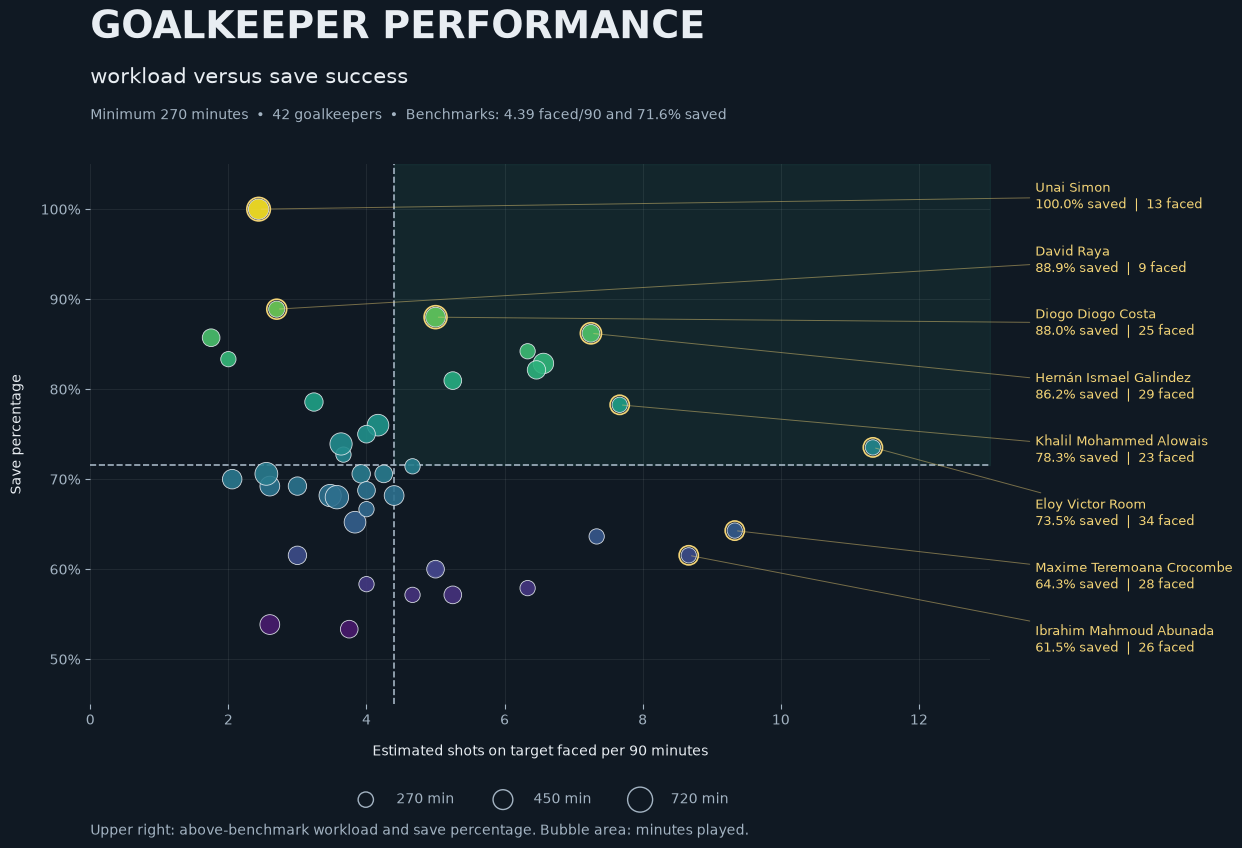

In [10]:
# Select goalkeepers with sufficient playing time
gk = players.loc[(players["position"] == "GK") & (players["minutes_played"] >= 270)
    ].dropna(subset=["saves", "goals_conceded", "minutes_played"]).copy()

# Estimate shots on target faced
gk["shots_faced"] = gk["saves"] + gk["goals_conceded"]
gk = gk[gk["shots_faced"] > 0].copy()

# Separate workload from save success
gk["shots_faced_per90"] = (gk["shots_faced"] / gk["minutes_played"] * 90)
gk["save_percentage"] = gk["saves"] / gk["shots_faced"] * 100

# Pooled benchmarks across eligible goalkeepers
workload_benchmark = (gk["shots_faced"].sum() / gk["minutes_played"].sum() * 90)
save_benchmark = gk["saves"].sum() / gk["shots_faced"].sum() * 100

# Label the four highest save percentages and four heaviest workloads
highlight = (gk.nlargest(4, "save_percentage").combine_first(gk.nlargest(4, "shots_faced_per90")).sort_values("save_percentage", ascending=False))

background = "#101923"
foreground = "#E8EDF2"
muted = "#A3B3C2"
accent = "#F3D477"

with plt.rc_context({"font.family": "DejaVu Sans", "text.color": foreground, "axes.labelcolor": foreground,
    "xtick.color": muted, "ytick.color": muted}):
    fig, ax = plt.subplots(figsize=(15, 9), facecolor=background)
    ax.set_facecolor(background)
    fig.subplots_adjust(left=0.09, right=0.69, top=0.80, bottom=0.20)

    xmax = gk["shots_faced_per90"].max() * 1.15
    ymin = max(0, np.floor(gk["save_percentage"].min() / 10) * 10 - 5)

    # Highlight the high-workload, high-save-percentage area
    ax.fill_between([workload_benchmark, xmax], save_benchmark, 105, color="#45D6B0", alpha=0.07)

    ax.axvline(workload_benchmark, color=muted, linestyle="--", linewidth=1.2)
    ax.axhline(save_benchmark, color=muted, linestyle="--", linewidth=1.2)

    # Bubble area represents playing time
    points = ax.scatter(gk["shots_faced_per90"], gk["save_percentage"], s=gk["minutes_played"] * 0.45, c=gk["save_percentage"],
        cmap="viridis", vmin=50, vmax=100, edgecolors=foreground, linewidths=0.6, alpha=0.9, zorder=3)

    ax.scatter(highlight["shots_faced_per90"], highlight["save_percentage"], s=highlight["minutes_played"] * 0.45 + 70, facecolors="none",
        edgecolors=accent, linewidths=1.2, zorder=4)

    # Place selected player labels outside the plotting area
    label_positions = np.linspace(0.94, 0.12, len(highlight))

    for (_, row), label_y in zip(highlight.iterrows(), label_positions):
        label = (
            f"{row['player_name']}\n"
            f"{row['save_percentage']:.1f}% saved"
            f"  |  {int(row['shots_faced'])} faced"
        )

        ax.annotate(label, xy=(row["shots_faced_per90"], row["save_percentage"]), xycoords="data", xytext=(1.05, label_y),
            textcoords="axes fraction", color=accent, fontsize=9, va="center", annotation_clip=False,
            arrowprops={"arrowstyle": "-", "color": accent, "linewidth": 0.7, "alpha": 0.45})

    ax.set_xlim(0, xmax)
    ax.set_ylim(ymin, 105)
    ax.set_yticks(np.arange(np.ceil(ymin / 10) * 10, 101, 10))
    ax.yaxis.set_major_formatter(PercentFormatter(100))

    ax.set_xlabel("Estimated shots on target faced per 90 minutes", labelpad=12)
    ax.set_ylabel("Save percentage", labelpad=12)
    ax.grid(color="white", alpha=0.07)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    # Bubble-size legend
    size_handles = [
        ax.scatter([], [], s=minutes * 0.45, facecolors="none", edgecolors=muted, label=f"{minutes} min")
        for minutes in [270, 450, 720]
    ]

    ax.legend(handles=size_handles, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False, labelcolor=muted,
        handletextpad=1.2, columnspacing=2.5)

    fig.text(0.09, 0.94, "GOALKEEPER PERFORMANCE", fontsize=27, fontweight="bold")
    fig.text(0.09, 0.89, "workload versus save success", fontsize=15)
    fig.text(0.09, 0.85,
        f"Minimum 270 minutes  •  {len(gk)} goalkeepers  •  "
        f"Benchmarks: {workload_benchmark:.2f} faced/90 and "
        f"{save_benchmark:.1f}% saved", fontsize=10, color=muted
)
    fig.text(
        0.09, 0.055,
        "Upper right: above-benchmark workload and save percentage. "
        "Bubble area: minutes played.",
        fontsize=10, color=muted
    )

    plt.show()

### Questions

# Lecture 8.1

### Agenda:

- Questions
- Show us your movies

# Lab 8.1

**E.0** Complete the previous labs if you are behind.

**E.1** Sign up for an LSU HPC account:

Each student should submit an HPC account request through the LSU HPC account request portal https://accounts.hpc.lsu.edu/login_request.php. In the Account Sponsor field, use my name and email address as your sponsor. 

We will be going over how to use the LSU HPC in the coming weeks. 


**E.2** Create an outline for your research proposal. Review the proposal rubric and create an outline for how you will meet all the grading criteria. Turn this in on Moodle, due by Wed Oct 14 midnight. 

**E.3** (Optional) Explore methods related to your final project, for example by exploring tutorials on datacamp or other resources.

**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

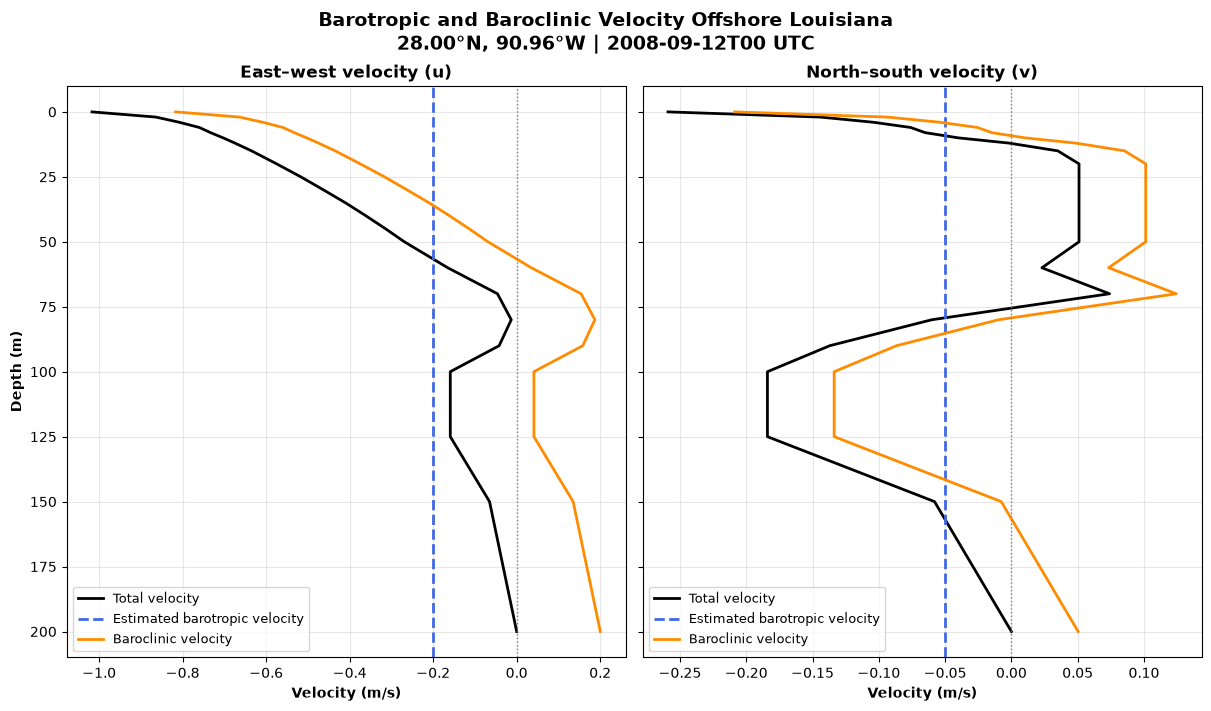

Depth interval used: 0–200 m
Estimated barotropic u: -0.2003 m/s
Estimated barotropic v: -0.0503 m/s


In [12]:
#Barotropic vs Baroclinic

# --------------------------------------------------
# 1. Choose location and date
# --------------------------------------------------
latitude = 28.0
longitude = -91.0
date = "2008-09-12"

url = ("https://tds.hycom.org/thredds/dodsC/" "GLBu0.08/expt_19.1/2008/3hrly")

ds = xr.open_dataset(url, engine="netcdf4", drop_variables=["tau"])

# Standardize coordinate names if needed
rename = {old: new
    for old, new in {"MT": "time", "Depth": "depth", "Latitude": "lat", "Longitude": "lon"}.items()
    if old in ds.dims or old in ds.coords}
ds = ds.rename(rename)

# Match the dataset's longitude convention
target_lon = longitude % 360 if float(ds.lon.max()) > 180 else longitude

# Download only one location and one time
point = ds[["water_u", "water_v"]].sel(lat=latitude, lon=target_lon, time=np.datetime64(date), method="nearest").load()

ds.close()

# --------------------------------------------------
# 2. Extract the vertical velocity profiles
# --------------------------------------------------
point = point.sortby("depth")

depth = point.depth.values.astype(float)
u = point.water_u.transpose("depth").values.astype(float)
v = point.water_v.transpose("depth").values.astype(float)

# Missing values are normally decoded automatically.
# Also remove any remaining extreme fill values.
valid = (np.isfinite(depth)
    & np.isfinite(u)
    & np.isfinite(v)
    & (np.abs(u) < 1e10)
    & (np.abs(v) < 1e10)
)

indices = np.flatnonzero(valid)

if len(indices) < 2:
    raise ValueError("Not enough valid depths. Choose another offshore location.")

if np.any(np.diff(indices) != 1):
    raise ValueError("The profile contains internal gaps; choose another location.")

depth = depth[valid]
u = u[valid]
v = v[valid]

# --------------------------------------------------
# 3. Estimate depth-averaged (barotropic) velocity
# --------------------------------------------------
# Trapezoidal integration accounts for uneven depth spacing.
dz = np.diff(depth)
profile_thickness = depth[-1] - depth[0]

u_barotropic = np.sum(
    0.5 * (u[:-1] + u[1:]) * dz
) / profile_thickness

v_barotropic = np.sum(
    0.5 * (v[:-1] + v[1:]) * dz
) / profile_thickness

# Baroclinic velocity = total minus depth average
u_baroclinic = u - u_barotropic
v_baroclinic = v - v_barotropic

# --------------------------------------------------
# 4. Plot both velocity components
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2, figsize=(12, 7), sharey=True, constrained_layout=True
)

profiles = [
    (u, u_barotropic, u_baroclinic, "East–west velocity (u)"),
    (v, v_barotropic, v_baroclinic, "North–south velocity (v)")
]

for ax, (total, barotropic, baroclinic, title) in zip(axes, profiles):

    ax.plot(
        total, depth,
        color="black", linewidth=2,
        label="Total velocity"
    )

    ax.axvline(
        barotropic,
        color="royalblue", linestyle="--", linewidth=2,
        label="Estimated barotropic velocity"
    )

    ax.plot(
        baroclinic, depth,
        color="darkorange", linewidth=2,
        label="Baroclinic velocity"
    )

    ax.axvline(0, color="gray", linestyle=":", linewidth=1)

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Velocity (m/s)", fontweight="bold")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

axes[0].set_ylabel("Depth (m)", fontweight="bold")
axes[0].invert_yaxis()

actual_lat = float(point.lat)
actual_lon = (float(point.lon) + 180) % 360 - 180
actual_time = np.datetime_as_string(point.time.values, unit="h")

fig.suptitle(
    "Barotropic and Baroclinic Velocity Offshore Louisiana\n"
    f"{actual_lat:.2f}°N, {abs(actual_lon):.2f}°W | {actual_time} UTC",
    fontsize=14,
    fontweight="bold"
)

plt.show()

print(f"Depth interval used: {depth[0]:.0f}–{depth[-1]:.0f} m")
print(f"Estimated barotropic u: {u_barotropic:.4f} m/s")
print(f"Estimated barotropic v: {v_barotropic:.4f} m/s")